Rows: 506


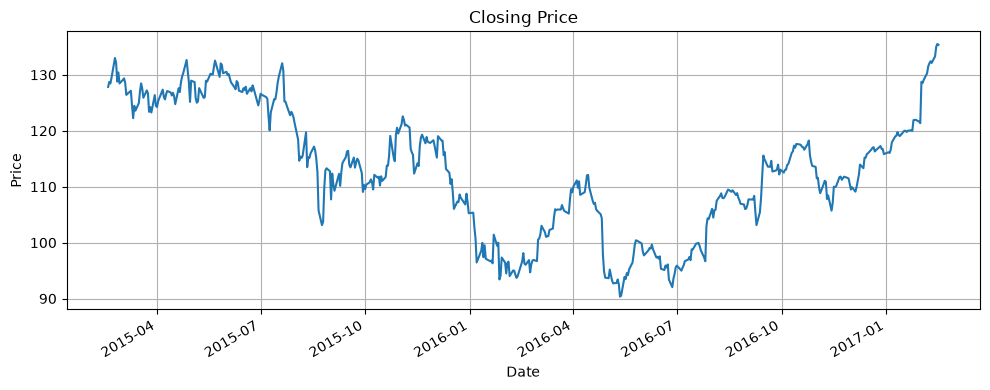

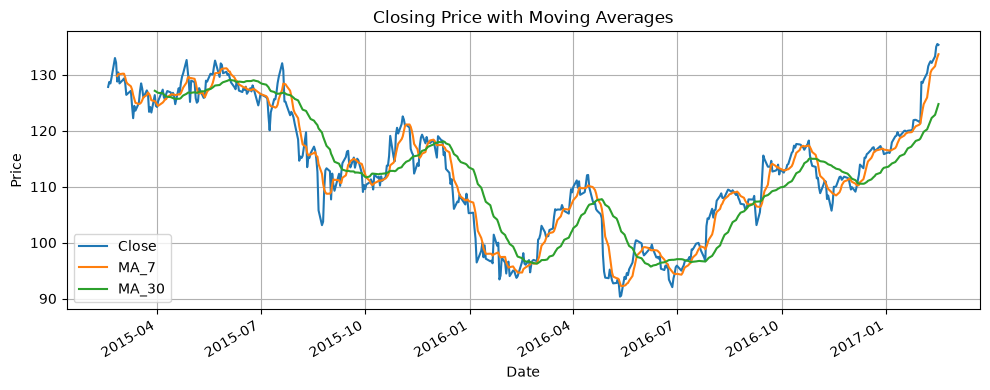

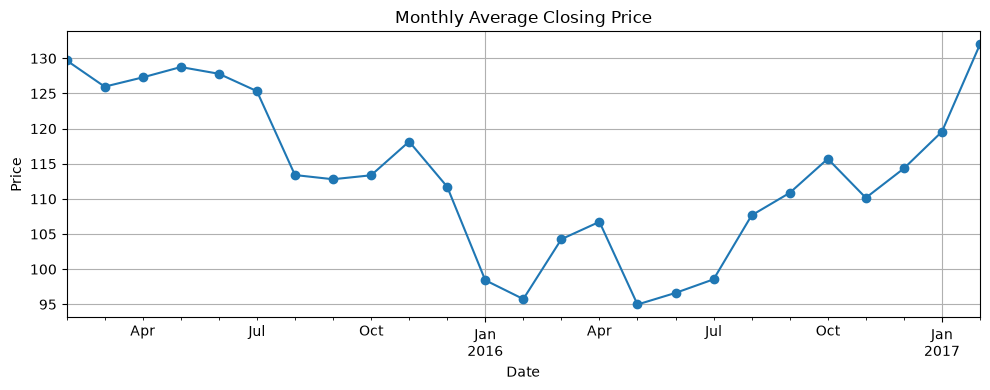


Correlation:
         Open  High   Low  Close  Volume
Open    1.00  1.00  1.00   0.99    0.03
High    1.00  1.00  0.99   1.00    0.07
Low     1.00  0.99  1.00   1.00   -0.01
Close   0.99  1.00  1.00   1.00    0.02
Volume  0.03  0.07 -0.01   0.02    1.00


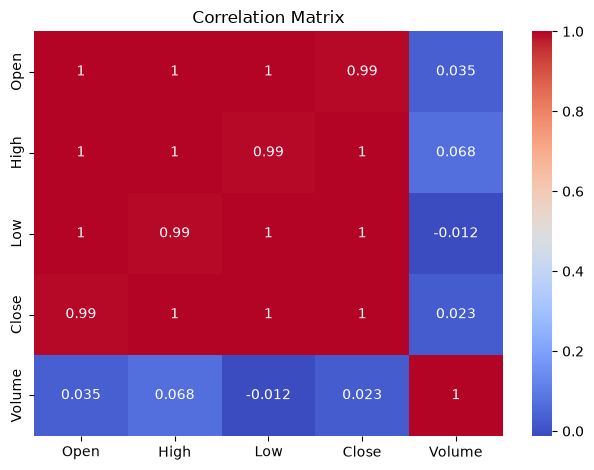


Forecast for the next 10 days:
 2017-02-17    135.35
2017-02-20    135.35
2017-02-21    135.35
2017-02-22    135.35
2017-02-23    135.35
2017-02-24    135.35
2017-02-27    135.35
2017-02-28    135.35
2017-03-01    135.35
2017-03-02    135.35
Freq: B, Name: predicted_mean, dtype: float64


/Users/musharrafkolhar/college_practicals/ml_practicals/venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Users/musharrafkolhar/college_practicals/ml_practicals/venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


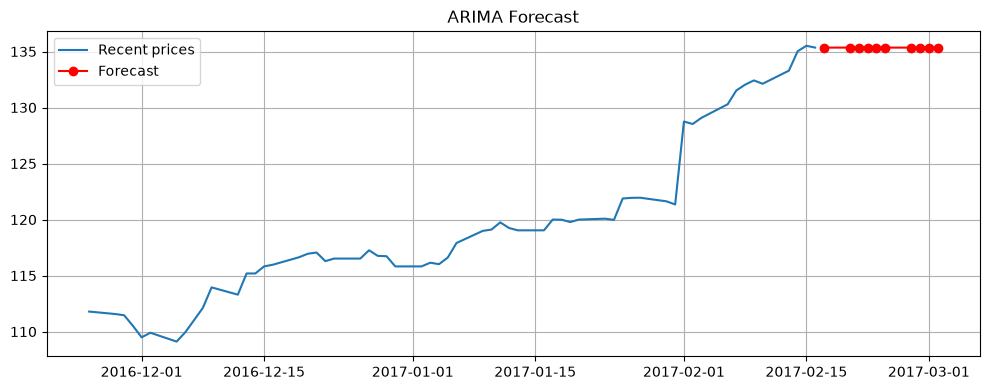

In [1]:
# Practical 13: Time Series Data Analysis
# Aim: Analyze stock price trends, moving averages, monthly patterns and
# correlations, and forecast future prices using ARIMA.
# Dataset: Stock_Prices.csv (Apple stock prices)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA

df = pd.read_csv("Stock_Prices.csv")
df = df.rename(columns={"AAPL.Open": "Open", "AAPL.High": "High", "AAPL.Low": "Low",
                        "AAPL.Close": "Close", "AAPL.Volume": "Volume"})
df["Date"] = pd.to_datetime(df["Date"])
df = df[["Date", "Open", "High", "Low", "Close", "Volume"]].dropna()
df = df.sort_values("Date").set_index("Date")
print("Rows:", len(df))

df["Close"].plot(figsize=(10, 4), title="Closing Price", grid=True)
plt.ylabel("Price")
plt.tight_layout()
plt.show()

df["MA_7"] = df["Close"].rolling(7).mean()
df["MA_30"] = df["Close"].rolling(30).mean()
df[["Close", "MA_7", "MA_30"]].plot(figsize=(10, 4), title="Closing Price with Moving Averages", grid=True)
plt.ylabel("Price")
plt.tight_layout()
plt.show()

monthly = df["Close"].resample("MS").mean()
monthly.plot(figsize=(10, 4), marker="o", title="Monthly Average Closing Price", grid=True)
plt.ylabel("Price")
plt.tight_layout()
plt.show()

corr = df[["Open", "High", "Low", "Close", "Volume"]].corr()
print("\nCorrelation:\n", corr.round(2))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

close = df["Close"].asfreq("B").ffill()
model = ARIMA(close, order=(1, 1, 1)).fit()
forecast = model.forecast(steps=10)
print("\nForecast for the next 10 days:\n", forecast.round(2))

plt.figure(figsize=(10, 4))
plt.plot(close.tail(60), label="Recent prices")
plt.plot(forecast, marker="o", color="red", label="Forecast")
plt.title("ARIMA Forecast")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()